
# Imam Abdulrahman Bin Faisal University
## ARTI 502 – Deep Learning
### Assignment 2: Training-Testing CNN with CIFAR Dataset using Pytorch

**Instructor:** Dr. Moatasem Alsmadi

**Group Number:** 4

**Group Members:**
1. Renad Salem Alqahtani – 2230004724
2. Jana Omar Alghamdi – 2230002367
3. Jood Yasser Alarfaj – 2230002692
4. Leen Mansour Alqahtani – 2230006599
5. Ghala Nassar Al-muriki – 2230006331
6. Wajd Mohammed Alqahtani – 2230005130


## Task 1: Getting the CIFAR Dataset

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
import os

DATA_PATH = './cifar_data'
os.makedirs(DATA_PATH, exist_ok=True)

transform = transforms.Compose([
    transforms.ToTensor()
])

trainset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transform
)

testset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transform
)

print("CIFAR-10 Dataset loaded successfully!")
print("Total training samples:", len(trainset))
print("Total testing samples:", len(testset))


100%|██████████| 170M/170M [00:21<00:00, 7.85MB/s]


CIFAR-10 Dataset loaded successfully!
Total training samples: 50000
Total testing samples: 10000


##Task 2: Defining the Network


**Network Architecture Definition**

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Conv block 1: in_channels=3 (RGB), out_channels=32, kernel_size=3, stride=1, padding=1
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1)
        # Conv block 2: in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)

        # Maxpooling layer: kernel_size=2, stride=2
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fully connected layers (Classifier)
        # Input image: 32x32 -> After pool 1: 16x16 -> After pool 2: 8x8 -> 64 channels * 8 * 8
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)  # 10 output classes for CIFAR-10

    def forward(self, x):
        # Feature extraction using convolution, activation, and maxpooling
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        # Flatten feature maps before feeding into the classifier
        x = x.view(x.size(0), -1)

        # Classification head
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Instantiate the model
model = CNN()
print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


**Base Training & Testing Functions**

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim

# Training function
def train(model, trainloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


# Testing function
def test(model, testloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in testloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss = running_loss / total
    test_accuracy = 100 * correct / total

    return test_loss, test_accuracy


##Task 3: Loading Data

Part 1: Find the images tensor size

In [ ]:
from torch.utils.data import DataLoader

# Load a batch of 8 images
trainloader = DataLoader(trainset, batch_size=8, shuffle=True)

# Get the images and labels
images, labels = next(iter(trainloader))

# Print their sizes
print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)


Images tensor size: torch.Size([8, 3, 32, 32])
Labels tensor size: torch.Size([8])


Part 2: Visualize images using Matplotlib

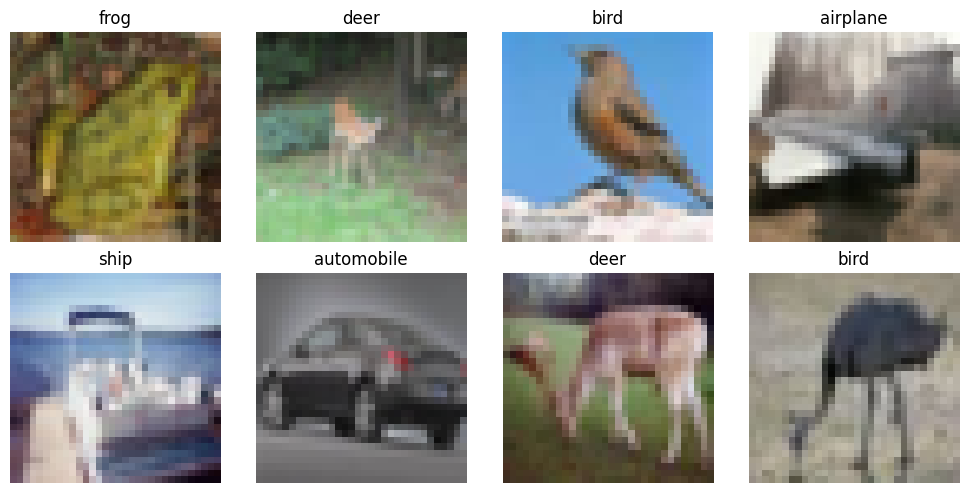

In [ ]:
import matplotlib.pyplot as plt

# Display the images
fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0)
    ax.imshow(image)
    ax.set_title(trainset.classes[labels[i].item()])
    ax.axis('off')

plt.tight_layout()
plt.show()


##Task 4: Dataset Augmentation

## Task 4: Dataset Augmentation

Data augmentation is applied to the CIFAR-10 training dataset
to introduce variations in the images and improve the CNN model's
ability to generalize.

The techniques include horizontal flipping, random cropping,
color jittering, rotation, Gaussian noise, and normalization.
Image format conversions are also demonstrated.

In [ ]:
# Task 4: Dataset Augmentation

import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Custom Gaussian Noise Transformation
class AddGaussianNoise:
    def __init__(self, mean=0.0, std=0.05):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        noise = torch.randn_like(tensor) * self.std + self.mean
        return torch.clamp(tensor + noise, 0.0, 1.0)

print("Gaussian Noise transformation defined successfully!")

Gaussian Noise transformation defined successfully!


In [ ]:
# CIFAR-10 Normalization Parameters
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

# Training Transformations (standard, lighter CIFAR-10 augmentation)
train_transform = transforms.Compose([

    transforms.RandomCrop(32, padding=4),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=CIFAR_MEAN,
        std=CIFAR_STD
    )
])

# Testing Transformations
test_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=CIFAR_MEAN,
        std=CIFAR_STD
    )
])

print("Data Augmentation transformations defined successfully!")

Data Augmentation transformations defined successfully!


In [ ]:
# Load CIFAR-10 Training Dataset
augmented_trainset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=False,
    transform=train_transform
)

# Load CIFAR-10 Testing Dataset
augmented_testset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=False,
    transform=test_transform
)

# Create DataLoaders
augmented_trainloader = DataLoader(
    augmented_trainset,
    batch_size=32,
    shuffle=True
)

augmented_testloader = DataLoader(
    augmented_testset,
    batch_size=32,
    shuffle=False
)

# Display Dataset Information
print("Augmented training samples:", len(augmented_trainset))
print("Testing samples:", len(augmented_testset))

# Check Tensor Shapes
train_images, train_labels = next(iter(augmented_trainloader))
test_images, test_labels = next(iter(augmented_testloader))

print("Training batch shape:", train_images.shape)
print("Testing batch shape:", test_images.shape)

Augmented training samples: 50000
Testing samples: 10000
Training batch shape: torch.Size([32, 3, 32, 32])
Testing batch shape: torch.Size([32, 3, 32, 32])


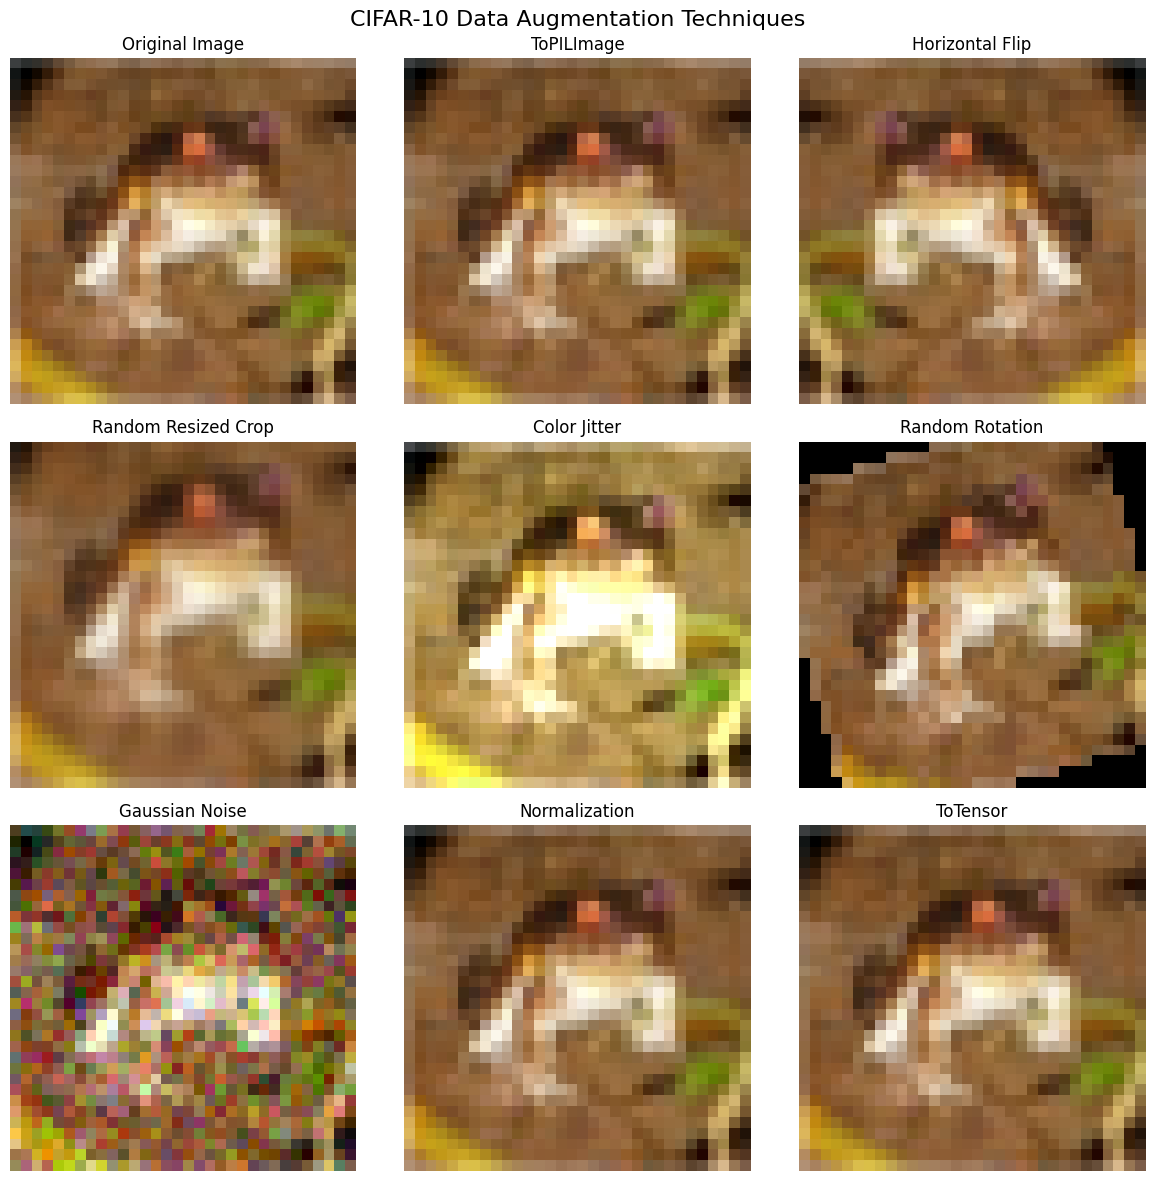

In [ ]:
# Visualize Different Data Augmentation Techniques

# Get original CIFAR-10 image
original_tensor, label = trainset[0]

# Convert Tensor to PIL Image
pil_image = transforms.ToPILImage()(original_tensor)

# Define Individual Augmentation Techniques
augmentation_methods = {

    "Original Image":
        transforms.Lambda(lambda img: img),

    "ToPILImage":
        transforms.ToPILImage(),

    "Horizontal Flip":
        transforms.RandomHorizontalFlip(p=1.0),

    "Random Resized Crop":
        transforms.RandomResizedCrop(
            size=32,
            scale=(0.8, 1.0)
        ),

    "Color Jitter":
        transforms.ColorJitter(
            brightness=0.4,
            contrast=0.4,
            saturation=0.4,
            hue=0.1
        ),

    "Random Rotation":
        transforms.RandomRotation(degrees=(15, 15)),

    "Gaussian Noise":
        AddGaussianNoise(mean=0.0, std=0.1),

    "Normalization":
        transforms.Normalize(
            mean=CIFAR_MEAN,
            std=CIFAR_STD
        ),

    "ToTensor":
        transforms.ToTensor()
}

# Create Figure
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, (name, transform_fn) in zip(
    axes.flat,
    augmentation_methods.items()
):

    if name == "ToPILImage":
        transformed = transform_fn(original_tensor)
        display_image = transformed

    elif name == "Gaussian Noise":
        transformed = transform_fn(original_tensor)
        display_image = transformed.permute(1, 2, 0)

    elif name == "Normalization":
        transformed = transform_fn(original_tensor)

        # Reverse normalization for correct visualization
        mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
        std = torch.tensor(CIFAR_STD).view(3, 1, 1)

        display_image = (
            transformed * std + mean
        ).clamp(0, 1).permute(1, 2, 0)

    elif name == "ToTensor":
        transformed = transform_fn(pil_image)
        display_image = transformed.permute(1, 2, 0)

    else:
        transformed = transform_fn(pil_image)
        display_image = transformed

    ax.imshow(display_image)
    ax.set_title(name)
    ax.axis("off")

plt.suptitle(
    "CIFAR-10 Data Augmentation Techniques",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
# Verify Augmented Dataset

assert len(augmented_trainset) == 50000
assert len(augmented_testset) == 10000

assert train_images.shape == (32, 3, 32, 32)
assert test_images.shape == (32, 3, 32, 32)

assert torch.isfinite(train_images).all()
assert torch.isfinite(test_images).all()

# Verify PIL conversion
assert pil_image.size == (32, 32)

print("All augmentation checks passed successfully!")
print("Augmented dataset is ready for CNN training.")

All augmentation checks passed successfully!
Augmented dataset is ready for CNN training.


### Task 4: Dataset Augmentation

In this task, different data augmentation techniques were implemented on the CIFAR-10 dataset using PyTorch.

The techniques include RandomHorizontalFlip, RandomResizedCrop, ColorJitter, RandomRotation, Gaussian Noise, and Normalize. Additionally, ToTensor and ToPILImage were used for image format conversion.

These transformations introduce variations in the training images, which can help improve the CNN model's generalization and reduce overfitting.

Data augmentation was applied only to the training dataset. The testing dataset was converted to tensors and normalized using the same normalization parameters without applying random augmentations.

Matplotlib was used to visualize the original images and the effects of different augmentation techniques.

##Task 5: Training Function and Tuning hyperparameters

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import pandas as pd
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Training samples:", len(augmented_trainset))
print("Testing samples:", len(augmented_testset))

print("Training batches:", len(augmented_trainloader))
print("Testing batches:", len(augmented_testloader))

Using device: cuda
GPU: Tesla T4
Training samples: 50000
Testing samples: 10000
Training batches: 1563
Testing batches: 313


In [ ]:
# Deeper CNN Architecture
class CNN_Deep(nn.Module):
    def __init__(self):
        super(CNN_Deep, self).__init__()

        # Convolutional layers
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fully connected layers
        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# Improved CNN: VGG-style blocks + BatchNorm + Dropout
def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )


class CNN_BN(nn.Module):
    def __init__(self):
        super(CNN_BN, self).__init__()

        # 32x32 -> 16x16 -> 8x8 -> 4x4
        self.features = nn.Sequential(
            conv_block(3, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


print("Deeper CNN architecture defined successfully!")
print(CNN_Deep())
print(CNN_BN())

Deeper CNN architecture defined successfully!
CNN_Deep(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
CNN_BN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_

In [ ]:
# Hyperparameter and Architecture Experiments

experiments = [
    {
        "name": "Exp 1 - Baseline",
        "model": CNN,
        "batch_size": 32,
        "lr": 0.001
    },
    {
        "name": "Exp 2 - Batch Size 64",
        "model": CNN,
        "batch_size": 64,
        "lr": 0.001
    },
    {
        "name": "Exp 3 - Learning Rate 0.0005",
        "model": CNN,
        "batch_size": 32,
        "lr": 0.0005
    },
    {
        "name": "Exp 4 - Deeper CNN",
        "model": CNN_Deep,
        "batch_size": 32,
        "lr": 0.001
    },
    {
        "name": "Exp 5 - Deeper CNN Tuned",
        "model": CNN_Deep,
        "batch_size": 64,
        "lr": 0.0005
    }
]

results = []

EPOCHS = 3

for exp in experiments:

    print("\n" + "=" * 50)
    print(exp["name"])
    print("=" * 50)

    trainloader = DataLoader(
        augmented_trainset,
        batch_size=exp["batch_size"],
        shuffle=True,
        pin_memory=True
    )

    testloader = DataLoader(
        augmented_testset,
        batch_size=exp["batch_size"],
        shuffle=False,
        pin_memory=True
    )

    model = exp["model"]().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=exp["lr"]
    )

    start_time = time.time()

    for epoch in range(EPOCHS):

        train_loss, train_acc = train(
            model, trainloader, criterion, optimizer, device
        )

        test_loss, test_acc = test(
            model, testloader, criterion, device
        )

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_acc:.2f}%"
        )

    elapsed_time = time.time() - start_time

    results.append({
        "Experiment": exp["name"],
        "Architecture": exp["model"].__name__,
        "Batch Size": exp["batch_size"],
        "Learning Rate": exp["lr"],
        "Train Loss": train_loss,
        "Train Accuracy": train_acc,
        "Test Loss": test_loss,
        "Test Accuracy": test_acc,
        "Training Time (seconds)": round(elapsed_time, 2)
    })

    print(f"Training Time: {elapsed_time:.2f} seconds")

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nAll experiments completed!")


Exp 1 - Baseline
Epoch [1/3] Train Loss: 1.4686 | Train Acc: 46.57% | Test Loss: 1.1396 | Test Acc: 59.56%
Epoch [2/3] Train Loss: 1.1382 | Train Acc: 59.49% | Test Loss: 0.9582 | Test Acc: 66.66%
Epoch [3/3] Train Loss: 1.0164 | Train Acc: 63.96% | Test Loss: 0.9157 | Test Acc: 67.75%
Training Time: 85.64 seconds

Exp 2 - Batch Size 64
Epoch [1/3] Train Loss: 1.5128 | Train Acc: 45.19% | Test Loss: 1.1998 | Test Acc: 57.34%
Epoch [2/3] Train Loss: 1.1861 | Train Acc: 57.54% | Test Loss: 1.0248 | Test Acc: 63.68%
Epoch [3/3] Train Loss: 1.0526 | Train Acc: 62.54% | Test Loss: 0.8916 | Test Acc: 68.23%
Training Time: 78.72 seconds

Exp 3 - Learning Rate 0.0005
Epoch [1/3] Train Loss: 1.4925 | Train Acc: 45.75% | Test Loss: 1.1323 | Test Acc: 59.05%
Epoch [2/3] Train Loss: 1.1568 | Train Acc: 58.73% | Test Loss: 0.9697 | Test Acc: 65.60%
Epoch [3/3] Train Loss: 1.0308 | Train Acc: 63.45% | Test Loss: 0.8988 | Test Acc: 68.75%
Training Time: 86.07 seconds

Exp 4 - Deeper CNN
Epoch [1/3] 

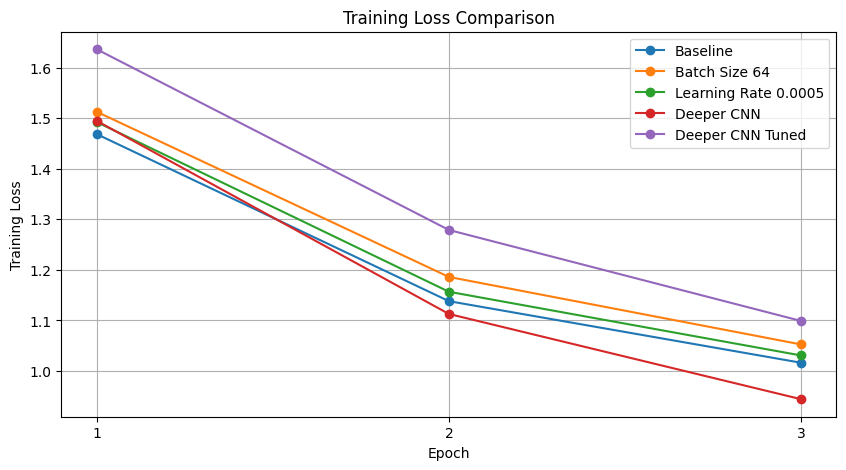

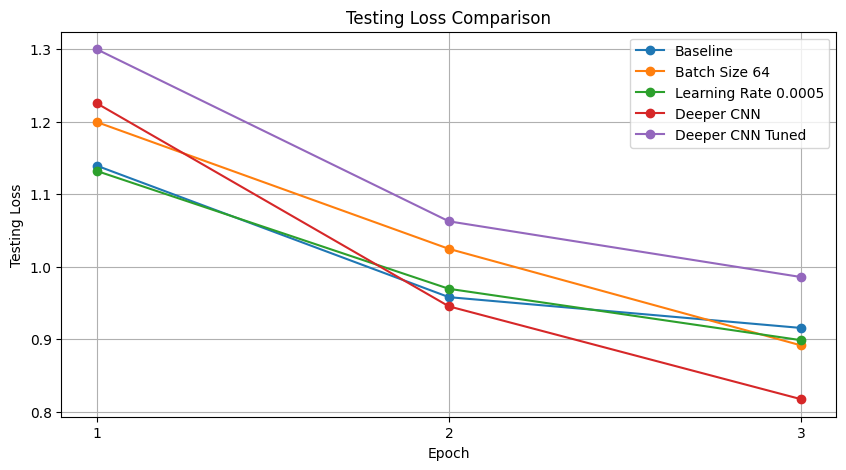

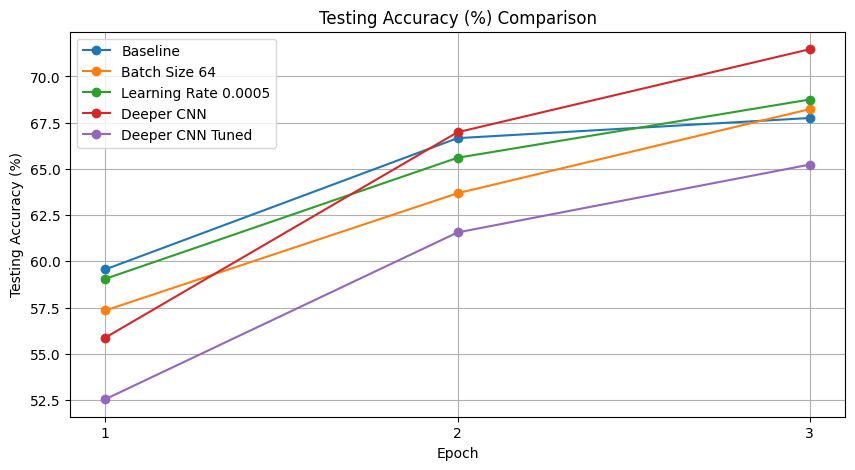

In [32]:
# Plot experiment results

epochs = [1, 2, 3]

history = {
    "Baseline": {
        "train_loss": [1.4686, 1.1382, 1.0164],
        "test_loss": [1.1396, 0.9582, 0.9157],
        "test_acc": [59.56, 66.66, 67.75]
    },
    "Batch Size 64": {
        "train_loss": [1.5128, 1.1861, 1.0526],
        "test_loss": [1.1998, 1.0248, 0.8916],
        "test_acc": [57.34, 63.68, 68.23]
    },
    "Learning Rate 0.0005": {
        "train_loss": [1.4925, 1.1568, 1.0308],
        "test_loss": [1.1323, 0.9697, 0.8988],
        "test_acc": [59.05, 65.60, 68.75]
    },
    "Deeper CNN": {
        "train_loss": [1.4949, 1.1129, 0.9443],
        "test_loss": [1.2257, 0.9455, 0.8174],
        "test_acc": [55.87, 66.98, 71.47]
    },
    "Deeper CNN Tuned": {
        "train_loss": [1.6364, 1.2790, 1.0990],
        "test_loss": [1.3002, 1.0628, 0.9859],
        "test_acc": [52.54, 61.56, 65.23]
    }
}

metrics = [
    ("train_loss", "Training Loss"),
    ("test_loss", "Testing Loss"),
    ("test_acc", "Testing Accuracy (%)")
]

for metric, title in metrics:

    plt.figure(figsize=(10, 5))

    for name, values in history.items():
        plt.plot(
            epochs,
            values[metric],
            marker='o',
            label=name
        )

    plt.title(title + " Comparison")
    plt.xlabel("Epoch")
    plt.ylabel(title)
    plt.xticks(epochs)
    plt.legend()
    plt.grid(True)
    plt.show()

In [30]:
# Experiment 6: Extended Training (10 Epochs)

# Create a fresh model
model_exp6 = CNN_Deep().to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model_exp6.parameters(),
    lr=0.001
)

# Store experiment history
exp6_history = {
    "train_loss": [],
    "train_accuracy": [],
    "test_loss": [],
    "test_accuracy": []
}

EPOCHS = 10

start_time = time.time()

print("Experiment 6: Deeper CNN - 10 Epochs")
print("=" * 60)

for epoch in range(EPOCHS):

    train_loss, train_acc = train(
        model_exp6,
        augmented_trainloader,
        criterion,
        optimizer,
        device
    )

    test_loss, test_acc = test(
        model_exp6,
        augmented_testloader,
        criterion,
        device
    )

    exp6_history["train_loss"].append(train_loss)
    exp6_history["train_accuracy"].append(train_acc)
    exp6_history["test_loss"].append(test_loss)
    exp6_history["test_accuracy"].append(test_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )

exp6_time = time.time() - start_time

print("=" * 60)
print(f"Total Training Time: {exp6_time:.2f} seconds")
print(f"Final Test Accuracy: {exp6_history['test_accuracy'][-1]:.2f}%")
print(f"Best Test Accuracy: {max(exp6_history['test_accuracy']):.2f}%")

Experiment 6: Deeper CNN - 10 Epochs
Epoch [1/10] | Train Loss: 1.4953 | Train Acc: 44.98% | Test Loss: 1.2686 | Test Acc: 53.60%
Epoch [2/10] | Train Loss: 1.1064 | Train Acc: 60.50% | Test Loss: 0.9238 | Test Acc: 67.73%
Epoch [3/10] | Train Loss: 0.9363 | Train Acc: 66.75% | Test Loss: 0.8108 | Test Acc: 72.07%
Epoch [4/10] | Train Loss: 0.8452 | Train Acc: 70.32% | Test Loss: 0.7684 | Test Acc: 72.96%
Epoch [5/10] | Train Loss: 0.7862 | Train Acc: 72.60% | Test Loss: 0.7119 | Test Acc: 75.59%
Epoch [6/10] | Train Loss: 0.7459 | Train Acc: 73.93% | Test Loss: 0.7290 | Test Acc: 75.37%
Epoch [7/10] | Train Loss: 0.7131 | Train Acc: 75.10% | Test Loss: 0.7249 | Test Acc: 75.53%
Epoch [8/10] | Train Loss: 0.6846 | Train Acc: 76.10% | Test Loss: 0.6608 | Test Acc: 77.56%
Epoch [9/10] | Train Loss: 0.6625 | Train Acc: 76.87% | Test Loss: 0.6583 | Test Acc: 76.92%
Epoch [10/10] | Train Loss: 0.6457 | Train Acc: 77.52% | Test Loss: 0.6430 | Test Acc: 78.25%
Total Training Time: 285.58 seco

In [ ]:
# Experiment 6: Training Performance Visualization

epochs = range(1, 11)

plt.figure(figsize=(15, 5))

# Training and Testing Loss
plt.subplot(1, 2, 1)

plt.plot(epochs, exp6_history["train_loss"],
         marker='o', label='Training Loss')

plt.plot(epochs, exp6_history["test_loss"],
         marker='s', label='Testing Loss')

plt.title("Training and Testing Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

# Testing Accuracy
plt.subplot(1, 2, 2)

plt.plot(epochs, exp6_history["test_accuracy"],
         marker='o', label='Testing Accuracy')

plt.title("Testing Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [25]:
# Experiment 7: Improved CNN (BatchNorm + Dropout, light augmentation,
# AdamW + OneCycleLR, label smoothing, 30 epochs)

EPOCHS_7 = 30
BATCH_7 = 128

train_loader7 = DataLoader(
    augmented_trainset, batch_size=BATCH_7, shuffle=True,
    num_workers=2, pin_memory=True
)
test_loader7 = DataLoader(
    augmented_testset, batch_size=BATCH_7, shuffle=False,
    num_workers=2, pin_memory=True
)

model_exp7 = CNN_BN().to(device)

criterion_train = nn.CrossEntropyLoss(label_smoothing=0.1)
criterion_eval = nn.CrossEntropyLoss()   # plain loss, comparable to earlier experiments

optimizer = optim.AdamW(model_exp7.parameters(), lr=2e-3, weight_decay=5e-4)
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=2e-3,
    epochs=EPOCHS_7,
    steps_per_epoch=len(train_loader7)
)

exp7_history = {
    "train_loss": [],
    "train_accuracy": [],
    "test_loss": [],
    "test_accuracy": []
}

start_time = time.time()

print("Experiment 7: CNN_BN - 30 Epochs")
print("=" * 60)

for epoch in range(EPOCHS_7):

    model_exp7.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader7:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_exp7(images)
        loss = criterion_train(outputs, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()          # step the scheduler once per batch

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total
    test_loss, test_acc = test(model_exp7, test_loader7, criterion_eval, device)

    exp7_history["train_loss"].append(train_loss)
    exp7_history["train_accuracy"].append(train_acc)
    exp7_history["test_loss"].append(test_loss)
    exp7_history["test_accuracy"].append(test_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS_7}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%"
    )

exp7_time = time.time() - start_time

print("=" * 60)
print(f"Total Training Time: {exp7_time:.2f} seconds")
print(f"Final Test Accuracy: {exp7_history['test_accuracy'][-1]:.2f}%")
print(f"Best Test Accuracy: {max(exp7_history['test_accuracy']):.2f}%")

Experiment 7: CNN_BN - 30 Epochs
Epoch [1/30] | Train Loss: 1.7652 | Train Acc: 40.57% | Test Loss: 1.2245 | Test Acc: 56.02%
Epoch [2/30] | Train Loss: 1.4418 | Train Acc: 57.88% | Test Loss: 1.2935 | Test Acc: 55.01%
Epoch [3/30] | Train Loss: 1.2936 | Train Acc: 65.73% | Test Loss: 1.1509 | Test Acc: 61.42%
Epoch [4/30] | Train Loss: 1.2072 | Train Acc: 70.17% | Test Loss: 0.8337 | Test Acc: 72.58%
Epoch [5/30] | Train Loss: 1.1460 | Train Acc: 73.43% | Test Loss: 0.8977 | Test Acc: 69.11%
Epoch [6/30] | Train Loss: 1.0927 | Train Acc: 76.06% | Test Loss: 0.8030 | Test Acc: 74.45%
Epoch [7/30] | Train Loss: 1.0501 | Train Acc: 78.11% | Test Loss: 0.7196 | Test Acc: 77.49%
Epoch [8/30] | Train Loss: 1.0066 | Train Acc: 80.45% | Test Loss: 0.6709 | Test Acc: 78.97%
Epoch [9/30] | Train Loss: 0.9622 | Train Acc: 82.03% | Test Loss: 0.6052 | Test Acc: 81.07%
Epoch [10/30] | Train Loss: 0.9218 | Train Acc: 83.93% | Test Loss: 0.6347 | Test Acc: 81.31%
Epoch [11/30] | Train Loss: 0.8896 |

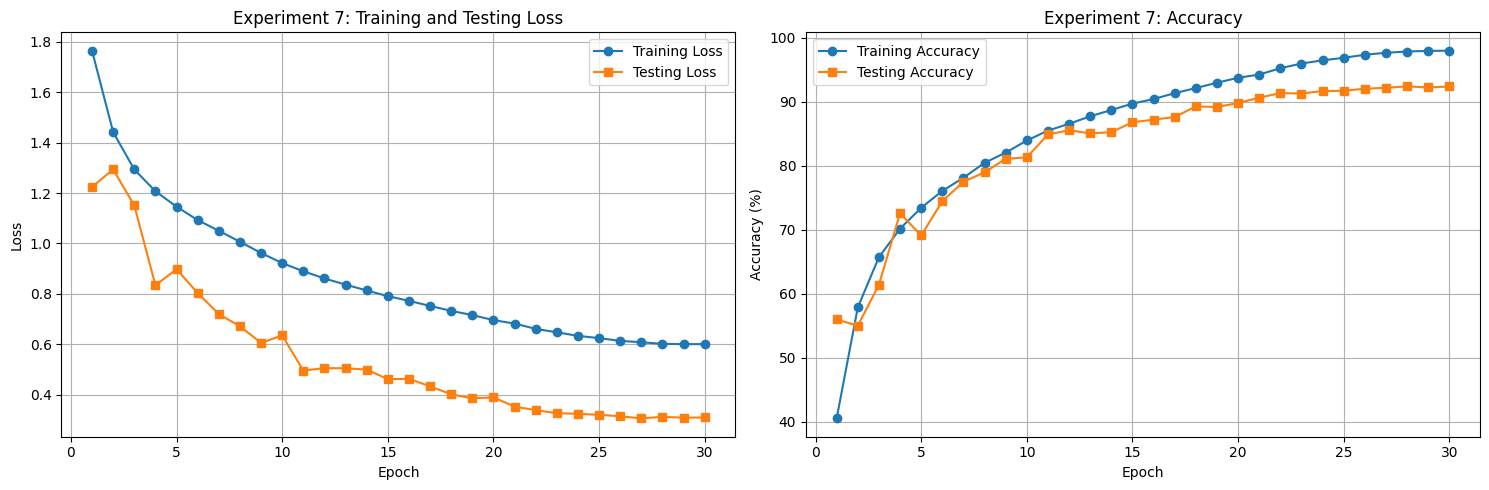

In [26]:
# Experiment 7: Training Performance Visualization

epochs = range(1, EPOCHS_7 + 1)

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, exp7_history["train_loss"], marker='o', label='Training Loss')
plt.plot(epochs, exp7_history["test_loss"], marker='s', label='Testing Loss')
plt.title("Experiment 7: Training and Testing Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, exp7_history["train_accuracy"], marker='o', label='Training Accuracy')
plt.plot(epochs, exp7_history["test_accuracy"], marker='s', label='Testing Accuracy')
plt.title("Experiment 7: Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [33]:
# Task 5: Experiment Results Comparison

import pandas as pd

comparison_data = [
    ["Exp 1 - Baseline", 2, 32, 0.001, 3, 67.75, 0.9157, 85.64],
    ["Exp 2 - Batch Size 64", 2, 64, 0.001, 3, 68.23, 0.8916, 78.72],
    ["Exp 3 - Learning Rate 0.0005", 2, 32, 0.0005, 3, 68.75, 0.8988, 86.07],
    ["Exp 4 - Deeper CNN", 3, 32, 0.001, 3, 71.47, 0.8174, 88.88],
    ["Exp 5 - Deeper CNN Tuned", 3, 64, 0.0005, 3, 65.23, 0.9859, 80.35],
    ["Exp 6 - Extended Training", 3, 32, 0.001, 10, 78.25, 0.6430, 285.58],
    [
        "Exp 7 - CNN_BN + AdamW/OneCycle",
        6, BATCH_7, 0.002, EPOCHS_7,
        round(exp7_history["test_accuracy"][-1], 2),
        round(exp7_history["test_loss"][-1], 4),
        round(exp7_time, 2)
    ]
]

comparison_df = pd.DataFrame(
    comparison_data,
    columns=[
        "Experiment",
        "Conv Layers",
        "Batch Size",
        "Learning Rate",
        "Epochs",
        "Test Accuracy (%)",
        "Test Loss",
        "Training Time (s)"
    ]
)

display(
    comparison_df.sort_values(
        by="Test Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)
)

,Experiment,Conv Layers,Batch Size,Learning Rate,Epochs,Test Accuracy (%),Test Loss,Training Time (s)
0,Exp 7 - CNN_BN + AdamW/OneCycle,6,128,0.0020,30,92.36,0.3089,725.09
1,Exp 6 - Extended Training,3,32,0.0010,10,78.25,0.6430,285.58
2,Exp 4 - Deeper CNN,3,32,0.0010,3,71.47,0.8174,88.88
3,Exp 3 - Learning Rate 0.0005,2,32,0.0005,3,68.75,0.8988,86.07
4,Exp 2 - Batch Size 64,2,64,0.0010,3,68.23,0.8916,78.72
5,Exp 1 - Baseline,2,32,0.0010,3,67.75,0.9157,85.64
6,Exp 5 - Deeper CNN Tuned,3,64,0.0005,3,65.23,0.9859,80.35


**Best Performing Model**

The best-performing model was the improved CNN (CNN_BN), with three VGG-style blocks of two convolutional layers each (64, 128 and 256 filters), Batch Normalization after every convolution, and Dropout (0.4) in the classifier.

It was trained for 30 epochs with the AdamW optimizer (maximum learning rate 0.002, weight decay 5e-4), a OneCycleLR schedule, label smoothing of 0.1 and a batch size of 128. The training data used standard augmentation (random crop with padding and horizontal flip).

It achieved a final test accuracy of 92.36% (best 92.38% at epoch 28) and a test loss of 0.3089, compared with 78.25% for the previous best model (Exp 6, Deeper CNN trained for 10 epochs).

**Discussion of Results**

- With only 3 epochs, all models reached 65–71% test accuracy. The Deeper CNN (Exp 4) was the best of them at 71.47%, ahead of the 2-layer baseline at 67.75%.
- Batch size 64 (Exp 2) and a learning rate of 0.0005 (Exp 3) gave small gains over the baseline (68.23% and 68.75% vs 67.75%). Combining them with the deeper CNN (Exp 5) lowered accuracy to 65.23%. With only 3 epochs, the lower learning rate and larger batch size gave too few updates for the deeper model to converge.
- Increasing the Deeper CNN from 3 to 10 epochs (Exp 6) raised test accuracy from 71.47% to 78.25%, but training accuracy (77.52%) was still about equal to test accuracy, so the small network was still limited by capacity.
- Exp 7 combined several changes: Batch Normalization with two convolutions per block, Dropout, standard augmentation (random crop and horizontal flip), AdamW with weight decay, a OneCycleLR schedule, label smoothing and 30 epochs. Together they raised test accuracy to 92.36% and cut test loss from 0.6430 to 0.3089.
- In Exp 7 the training accuracy (97.94%) is now higher than the test accuracy (92.36%), so a modest generalization gap appeared. Test accuracy stopped improving after about epoch 27, when the learning rate had decayed.
- The cost was training time: Exp 7 took about 725 seconds versus 286 seconds for Exp 6, because the model is larger and trained for three times as many epochs.
